# Embedding Neurons with a Pretrained NuCLR Model

[NuCLR](https://arxiv.org/abs/2512.01199) is a self-supervised model that learns an embedding for each neuron from its spiking activity, in the context of the other neurons recorded alongside it.
Neurons with similar embeddings tend to share properties that the model never sees, such as the brain region they were recorded from.

This notebook shows how to:
1. Load a NuCLR model pretrained on the [IBL Brain-Wide Bench](https://github.com/brainbench-org/ibl-bwb) from Hugging Face.
2. Run a forward pass on a single window of a held-out recording.
3. Embed every neuron of the recording with `NuCLR.embed`, and check how well the embeddings predict brain regions.

> ⚠ **Note:**
> Although this notebook can run on a CPU, it is recommended that you use a GPU runtime.
> If you're on Google Colab, do: Runtime > Change runtime type > T4 GPU

## Setup

Install dependencies:

In [ ]:
!pip install git+https://github.com/neuro-galaxy/torch_brain
!pip install huggingface_hub omegaconf umap-learn matplotlib scikit-learn

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import umap
from huggingface_hub import hf_hub_download
from omegaconf import OmegaConf
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize

from torch_brain.batching import collate
from torch_brain.data import Data
from torch_brain.models import NuCLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Loading the Pretrained Model

[`nerdslab/ibl-bwb-nuclr`](https://huggingface.co/nerdslab/ibl-bwb-nuclr) has five NuCLR checkpoints (seeds 42 to 46), each pretrained on the IBL Brain-Wide Bench pretraining recordings.
Along with the weights, each checkpoint stores the config the model was trained with, so we can build the model directly from it.
We should get a ~10.5M parameter model with a 20 s context window.

> **Note:** The config is stored as an `omegaconf` object, which `torch.load` can't read with `weights_only=True`.
> We load it with `weights_only=False`, which you should only do for checkpoints you trust.

In [3]:
SEED = 42  # one of 42 to 46

path = hf_hub_download("nerdslab/ibl-bwb-nuclr", f"nuclr_{SEED}.pt")
ckpt = torch.load(path, map_location="cpu", weights_only=False)

config = OmegaConf.to_container(ckpt["cfg"]["model"])
config.pop("_target_")
model = NuCLR(**config)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device)

num_params = sum(p.numel() for p in model.parameters())
print(f"{num_params / 1e6:.1f}M parameters, {model.ctx_duration:.0f} s context window")

10.5M parameters, 20 s context window


## Downloading a Held-out Recording

We use an IBL recording that was *held out* of pretraining, so the model has never seen these neurons.
Its Neuropixels probe passes through somatosensory cortex, hippocampus and thalamus.
The file is ~540 MB, and only contains units that pass IBL's quality control.

In [4]:
RECORDING_ID = "19e66dc9-bf9f-430b-9d6a-acfa85de6fb7"
URL = (
    "https://brain-wide-bench.s3.amazonaws.com/brainsets/selected_units/"
    f"ibl_brain_wide_bench_2026/eval/{RECORDING_ID}.h5"
)

path = Path("data") / f"{RECORDING_ID}.h5"
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urlretrieve(URL, path.with_suffix(".part"))
    path.with_suffix(".part").replace(path)

with h5py.File(path) as f:
    data = Data.from_hdf5(f, lazy=False)

duration = data.domain.end[-1] - data.domain.start[0]
print(f"{len(data.units.id)} units, {duration / 60:.0f} minutes")

297 units, 84 minutes


Each unit is labeled with the brain region it was recorded from, at several levels of the Allen atlas.
We use the `region_beryl` level.
These labels are *only* used to evaluate the embeddings: the model never sees them.

In [5]:
regions, counts = np.unique(data.units.region_beryl.astype(str), return_counts=True)
print(", ".join(f"{r}: {c}" for r, c in zip(regions, counts)))

CA3: 12, LD: 79, PO: 116, SSp-ul: 67, VPM: 20, root: 3


## A Single Forward Pass

NuCLR processes a recording one `ctx_duration`-long window (20 s) at a time.
`get_input_fn` returns the transform that turns a `Data` slice into model inputs:
- **`bins`**: spike counts in 20 ms bins, with one row per unit that spikes in the window.
- **`group_lengths`**: the number of units in each spatial attention group. With `group_by="probe_id"`, units only attend to units on the same probe.

When training, this transform is meant to be the last transform of a `Dataset`, with batches assembled by `collate`.

Let's run it on the first window of the recording.
Since the window is 20 s long and the bins are 20 ms, we should get 1000 bins per unit.

In [6]:
input_fn = model.get_input_fn(group_by="probe_id")

start = data.domain.start[0]
sample = input_fn(data.slice(start, start + model.ctx_duration))
batch = collate([sample])
print("bins:", tuple(batch["bins"].shape), "group_lengths:", batch["group_lengths"].tolist())

model.eval()
with torch.no_grad():
    z = model(batch["bins"].to(device), batch["group_lengths"].to(device))
print("embeddings:", tuple(z.shape))

bins: (256, 1000) group_lengths: [256]


embeddings: (256, 256)


Notice that only 256 of the 297 units are in `bins`: the others don't spike in this window, so they are dropped.
The model returns one 256-dimensional embedding per unit.

## Embedding Every Unit

`NuCLR.embed` does this over the whole recording.
It slides 20 s windows with a 10 s step, and averages the embedding of each unit over the windows in which it spikes.
Units that never spike get `NaN` embeddings.

This takes ~3 s on an RTX5090, and ~3 minutes on a 32-core CPU.
On a CPU, you can set `MAX_MINUTES` to only embed the start of the recording.

In [7]:
MAX_MINUTES = None  # e.g. 10 to only embed the first 10 minutes

if MAX_MINUTES is not None:
    data = data.slice(data.domain.start[0], data.domain.start[0] + 60 * MAX_MINUTES)

emb = model.embed(data).cpu().numpy()
print("embeddings:", emb.shape)

embeddings: (297, 256)


## Do the Embeddings Know Where Neurons Are?

If the embeddings capture brain regions, the nearest neighbors of a unit in embedding space should mostly come from its own region.
Let's check this with a 5-nearest-neighbor classifier and 5-fold cross-validation.
Units labeled `root` were not assigned to a region, so we leave them out.

In [8]:
region = data.units.region_beryl.astype(str)
keep = ~np.isnan(emb).any(1) & ~np.isin(region, ["root", "void"])
x, y = normalize(emb[keep]), region[keep]

acc = cross_val_score(KNeighborsClassifier(5), x, y, cv=5).mean()
majority = np.unique(y, return_counts=True)[1].max() / len(y)
print(f"5-NN brain region accuracy: {acc:.2f} (majority class: {majority:.2f})")

5-NN brain region accuracy: 0.73 (majority class: 0.39)


With seed 42, we get ~0.73, well above the 0.39 of always predicting the most common region.

Finally, let's visualize the embeddings with UMAP, colored by brain region.

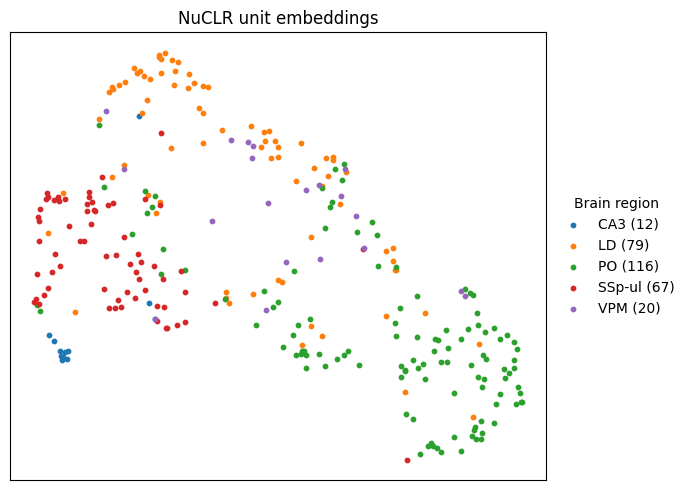

In [9]:
xy = umap.UMAP(random_state=0).fit_transform(x)

fig, ax = plt.subplots(figsize=(7, 5))
for r in np.unique(y):
    ax.scatter(*xy[y == r].T, s=10, label=f"{r} ({(y == r).sum()})")
ax.set(xticks=[], yticks=[], title="NuCLR unit embeddings")
ax.legend(title="Brain region", frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

The model only sees spikes, yet units from the same region end up close to each other, *including* neighboring thalamic nuclei (LD, PO and VPM).

## Things to Try

- Load another checkpoint by changing `SEED`.
- Color the embeddings by a coarser region level, such as `region_cosmos`.
- Embed your own recordings: `NuCLR.embed` works on any `Data` object with `spikes` and `units` (see `NuCLR.get_input_fn` for the expected attributes).